# Cleveland Heart Disease Dataset: Preprocessing & Comprehensive Feature Visualization

This notebook provides an end-to-end **data preprocessing and feature-by-feature exploratory analysis** for the **UCI Cleveland Heart Disease** dataset.

### Key Highlights:
1. **Header & Schema Rectification:** In previous notebooks, loading without `header=None` caused the first patient record to be treated as column headers (yielding 302 rows instead of 303). Here, the complete 303 patient records are parsed with standard clinical feature names.
2. **Target Binarization:** Converting the angiographic disease status (`0 = Healthy/Absence`, `1, 2, 3, 4 = Presence of CAD`) into standard binary convention (`0 = Healthy`, `1 = Heart Disease`).
3. **Missing Value Handling:** Missing records in `major_vessels` (4 values) and `thal` (2 values) are detected (`'?' -> NaN`) and properly imputed.
4. **Feature-by-Feature Statistical Analysis & Visualization:** In-depth univariate and bivariate plots (histograms, KDEs, boxplots, stacked bar charts) along with hypothesis testing ($t$-test and $\chi^2$ tests) for all 13 predictors.
5. **Correlation Analysis:** Full correlation heatmap with clinically relevant correlation insights.
6. **Zero-Leakage Preprocessing Pipeline:** Stratified 80/20 splitting prior to transformations, One-Hot Encoding, Min-Max Scaling, and training-only SMOTE balancing.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

# Plotting configuration
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

## 1. Data Ingestion & Schema Definition

The Cleveland dataset contains 13 clinical attributes and 1 target attribute recorded across 303 patient observations. The file `processed.cleveland.data` is comma-delimited without a header row.

In [2]:
# Standard clinical attribute names matching medical literature
COLUMNS = [
    'age',                  # 1. Age in years (Real)
    'sex',                  # 2. Sex: 1 = Male, 0 = Female (Binary)
    'chest_pain_type',      # 3. Chest pain type (Nominal: 1: typ angina, 2: atyp angina, 3: non-anginal, 4: asympt)
    'resting_bp',           # 4. Resting blood pressure in mm Hg (Real)
    'serum_chol',           # 5. Serum cholesterol in mg/dl (Real)
    'fasting_blood_sugar',  # 6. Fasting blood sugar > 120 mg/dl: 1 = true, 0 = false (Binary)
    'resting_ecg',          # 7. Resting ECG (Nominal: 0: normal, 1: ST-T wave abn, 2: LV hypertrophy)
    'max_heart_rate',       # 8. Maximum heart rate achieved (Real)
    'exercise_angina',      # 9. Exercise induced angina: 1 = yes, 0 = no (Binary)
    'oldpeak',              # 10. ST depression induced by exercise relative to rest (Real)
    'slope',                # 11. Slope of peak exercise ST segment (Ordered: 1: upsloping, 2: flat, 3: downsloping)
    'major_vessels',        # 12. Number of major vessels (0-3) colored by fluoroscopy (Real/Count)
    'thal',                 # 13. Thallium scan: 3 = normal, 6 = fixed defect, 7 = reversible defect (Nominal)
    'target'                # 14. Target: 0 = Absence, 1-4 = Presence
]

# Load Cleveland dataset, parsing '?' as NaN
data_path = 'datasets/heart+disease/processed.cleveland.data'
df = pd.read_csv(data_path, header=None, names=COLUMNS, na_values='?')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 303 rows, 14 columns


,age,sex,chest_pain_type,resting_bp,serum_chol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,slope,major_vessels,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Target Variable Binarization & Missing Value Analysis

In the original database:
* `0` denotes **Absence of Heart Disease** (Healthy)
* `1, 2, 3, 4` denotes increasing severity of **Angiographic CAD**

We binarize the target: `0 -> 0` (Healthy) and `> 0 -> 1` (Heart Disease).

Missing Values by Column:
major_vessels    4
thal             2
dtype: int64

Class Balance:
Healthy (0): 164 (54.13%)
Heart Disease (1): 139 (45.87%)


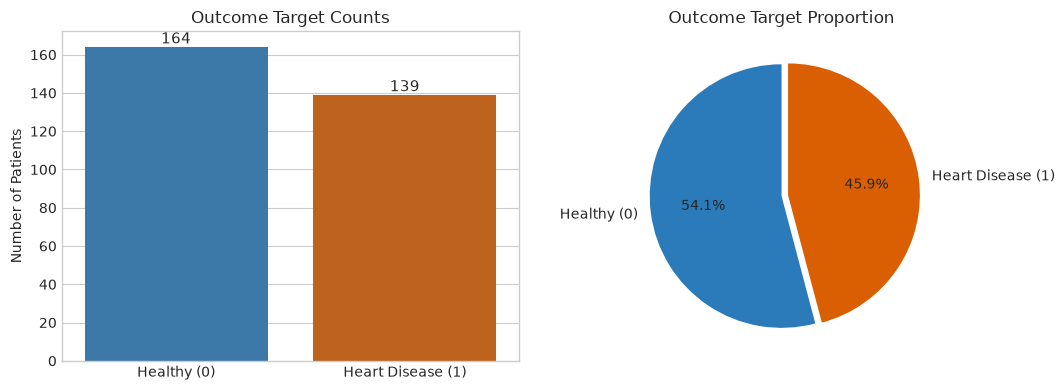

In [3]:
# Binarize target
df['target'] = (df['target'] > 0).astype(int)

print("Missing Values by Column:")
missing_counts = df.isna().sum()
print(missing_counts[missing_counts > 0])

counts = df['target'].value_counts()
pcts = df['target'].value_counts(normalize=True) * 100
print(f"\nClass Balance:\nHealthy (0): {counts[0]} ({pcts[0]:.2f}%)\nHeart Disease (1): {counts[1]} ({pcts[1]:.2f}%)")

# Plot Target Distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=['Healthy (0)', 'Heart Disease (1)'], y=counts.values, hue=['Healthy (0)', 'Heart Disease (1)'], palette=['#2b7bba', '#d95f02'], legend=False, ax=axes[0])
axes[0].set_title('Outcome Target Counts', fontsize=12)
axes[0].set_ylabel('Number of Patients')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=11)

axes[1].pie(counts.values, labels=['Healthy (0)', 'Heart Disease (1)'], autopct='%1.1f%%', colors=['#2b7bba', '#d95f02'], startangle=90, explode=[0, 0.05])
axes[1].set_title('Outcome Target Proportion', fontsize=12)
plt.tight_layout()
plt.show()

## 3. Missing Value Imputation
We impute missing values in `major_vessels` and `thal` using **median** for numerical features and **mode** for categorical features.

In [4]:
num_cols = ['age', 'resting_bp', 'serum_chol', 'max_heart_rate', 'oldpeak', 'major_vessels']
cat_cols = ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'resting_ecg', 'exercise_angina', 'slope', 'thal']

# Perform imputation
df_clean = df.copy()
df_clean[num_cols] = SimpleImputer(strategy='median').fit_transform(df_clean[num_cols])
df_clean[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(df_clean[cat_cols])

print("Remaining missing values:", df_clean.isna().sum().sum())

# Summary statistics
summary_stats = df_clean.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['Skewness'] = df_clean.skew()
display(summary_stats.round(2))

Remaining missing values: 0


,mean,std,min,25%,50%,75%,max,IQR,Skewness
age,54.44,9.04,29.0,48.0,56.0,61.0,77.0,13.0,-0.21
sex,0.68,0.47,0.0,0.0,1.0,1.0,1.0,1.0,-0.77
chest_pain_type,3.16,0.96,1.0,3.0,3.0,4.0,4.0,1.0,-0.84
resting_bp,131.69,17.60,94.0,120.0,130.0,140.0,200.0,20.0,0.71
serum_chol,246.69,51.78,126.0,211.0,241.0,275.0,564.0,64.0,1.14
fasting_blood_sugar,0.15,0.36,0.0,0.0,0.0,0.0,1.0,0.0,1.99
resting_ecg,0.99,0.99,0.0,0.0,1.0,2.0,2.0,2.0,0.02
max_heart_rate,149.61,22.88,71.0,133.5,153.0,166.0,202.0,32.5,-0.54
exercise_angina,0.33,0.47,0.0,0.0,0.0,1.0,1.0,1.0,0.74
oldpeak,1.04,1.16,0.0,0.0,0.8,1.6,6.2,1.6,1.27


## 4. Feature-by-Feature In-Depth Visualizations & Statistical Tests

We evaluate the distribution of each feature and its statistical association with heart disease:
1. **Continuous Features:** Welch's two-sample $t$-test ($t$-statistic and $p$-value).
2. **Categorical & Binary Features:** Pearson's $\chi^2$ contingency test of independence and CVD prevalence rates.

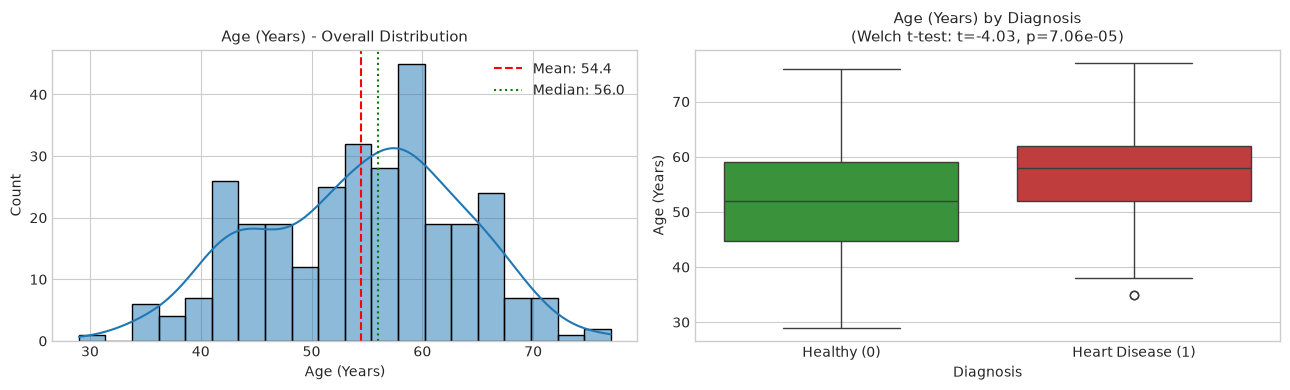

-> age: Healthy Mean = 52.59 ± 9.51 | CVD Mean = 56.63 ± 7.94 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


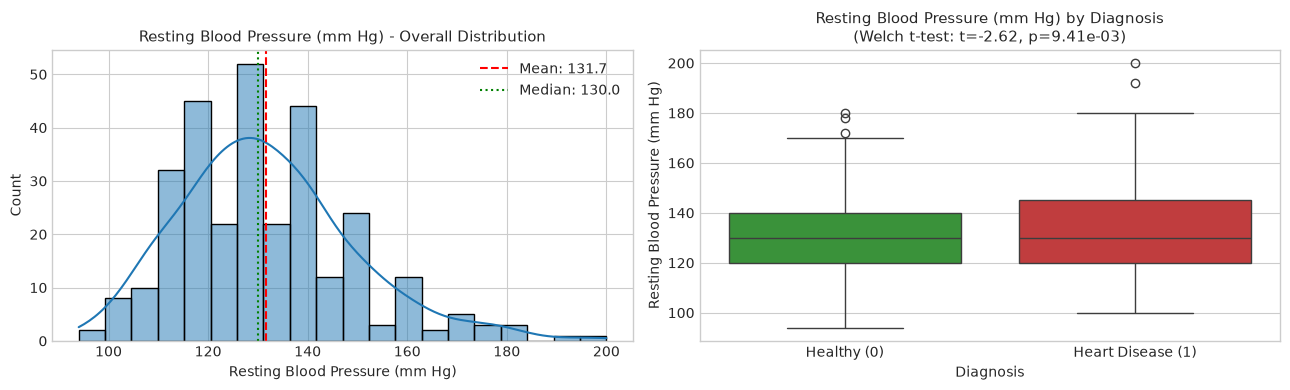

-> resting_bp: Healthy Mean = 129.25 ± 16.20 | CVD Mean = 134.57 ± 18.77 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


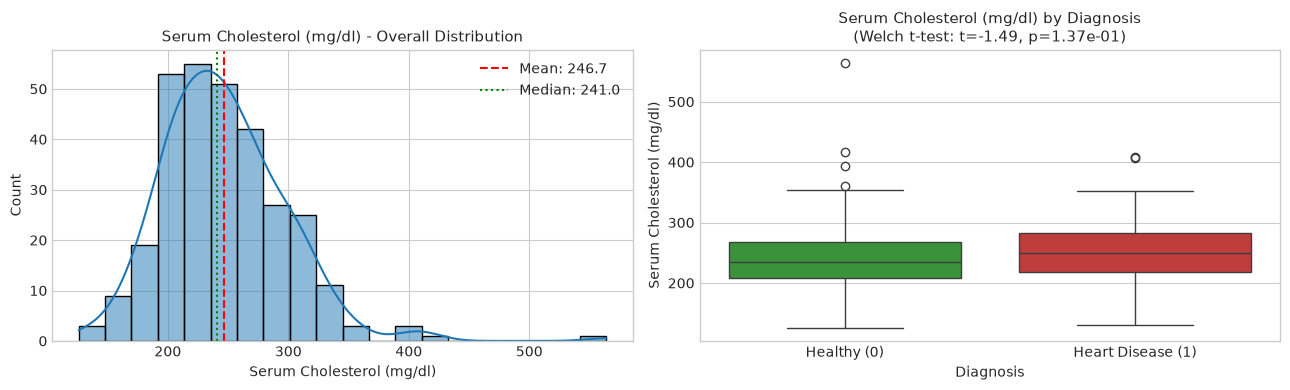

-> serum_chol: Healthy Mean = 242.64 ± 53.46 | CVD Mean = 251.47 ± 49.49 [Not Statistically Significant (p >= 0.05)]
--------------------------------------------------------------------------------


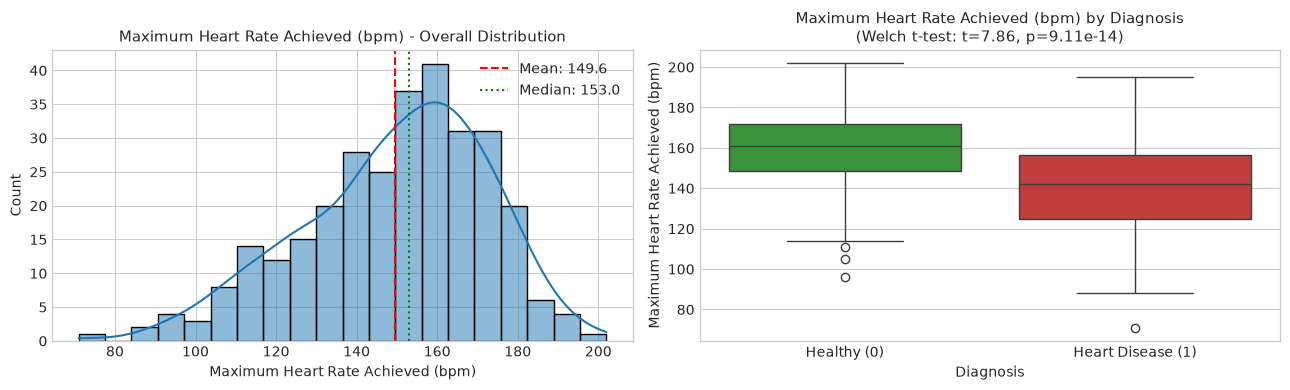

-> max_heart_rate: Healthy Mean = 158.38 ± 19.20 | CVD Mean = 139.26 ± 22.59 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


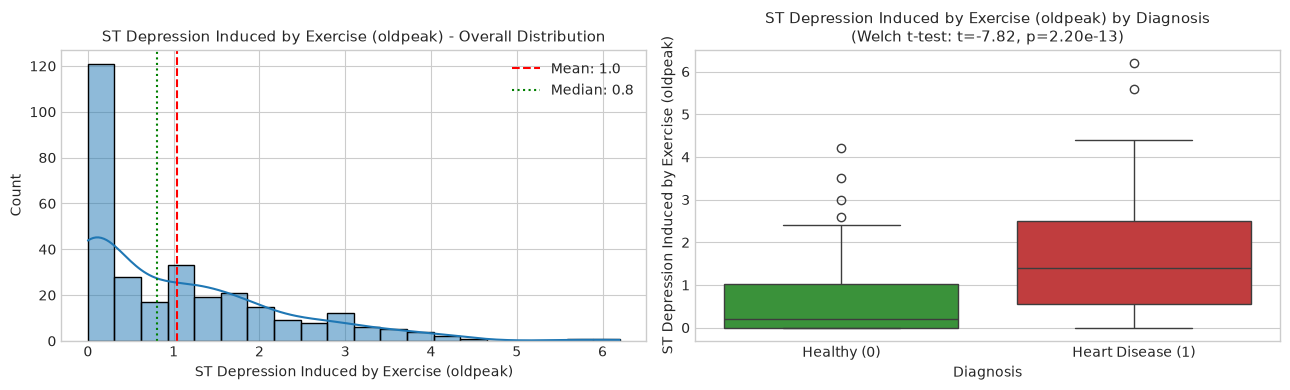

-> oldpeak: Healthy Mean = 0.59 ± 0.78 | CVD Mean = 1.57 ± 1.30 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


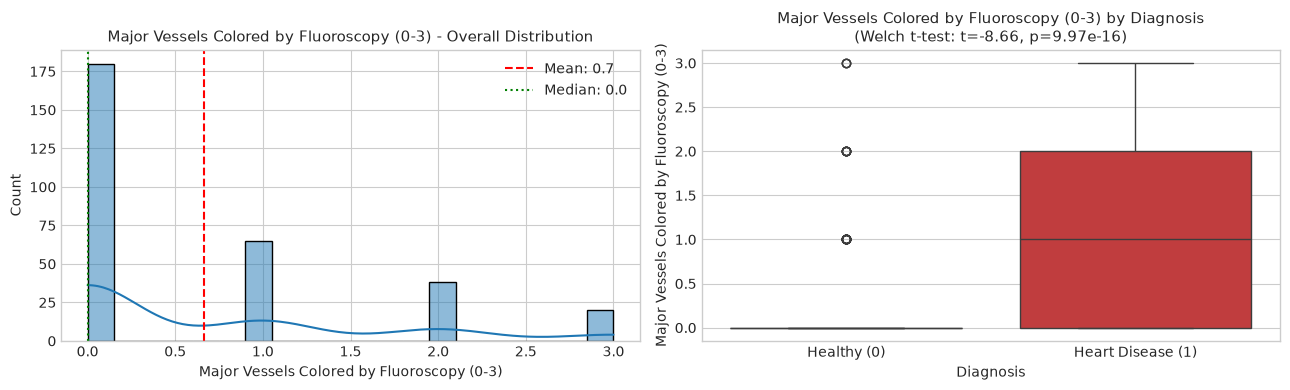

-> major_vessels: Healthy Mean = 0.27 ± 0.63 | CVD Mean = 1.13 ± 1.02 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


In [5]:
num_features = [
    ('age', 'Age (Years)'),
    ('resting_bp', 'Resting Blood Pressure (mm Hg)'),
    ('serum_chol', 'Serum Cholesterol (mg/dl)'),
    ('max_heart_rate', 'Maximum Heart Rate Achieved (bpm)'),
    ('oldpeak', 'ST Depression Induced by Exercise (oldpeak)'),
    ('major_vessels', 'Major Vessels Colored by Fluoroscopy (0-3)')
]

for col, title in num_features:
    healthy_vals = df_clean[df_clean['target'] == 0][col]
    cvd_vals = df_clean[df_clean['target'] == 1][col]
    t_stat, p_val = stats.ttest_ind(healthy_vals, cvd_vals, equal_var=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    # Subplot 1: Distribution histogram + KDE
    sns.histplot(df_clean[col], kde=True, ax=axes[0], color='#1f77b4', bins=20)
    axes[0].axvline(df_clean[col].mean(), color='red', linestyle='--', label=f"Mean: {df_clean[col].mean():.1f}")
    axes[0].axvline(df_clean[col].median(), color='green', linestyle=':', label=f"Median: {df_clean[col].median():.1f}")
    axes[0].set_title(f"{title} - Overall Distribution", fontsize=11)
    axes[0].set_xlabel(title)
    axes[0].legend()
    
    # Subplot 2: Comparison by CVD status
    sns.boxplot(x='target', y=col, data=df_clean, ax=axes[1], hue='target', palette=['#2ca02c', '#d62728'], legend=False)
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(['Healthy (0)', 'Heart Disease (1)'])
    axes[1].set_title(f"{title} by Diagnosis\n(Welch t-test: t={t_stat:.2f}, p={p_val:.2e})", fontsize=11)
    axes[1].set_xlabel('Diagnosis')
    axes[1].set_ylabel(title)
    
    plt.tight_layout()
    plt.show()
    
    sig_text = "Statistically Significant (p < 0.05)" if p_val < 0.05 else "Not Statistically Significant (p >= 0.05)"
    print(f"-> {col}: Healthy Mean = {healthy_vals.mean():.2f} ± {healthy_vals.std():.2f} | CVD Mean = {cvd_vals.mean():.2f} ± {cvd_vals.std():.2f} [{sig_text}]")
    print("-" * 80)

### Categorical & Binary Features Analysis

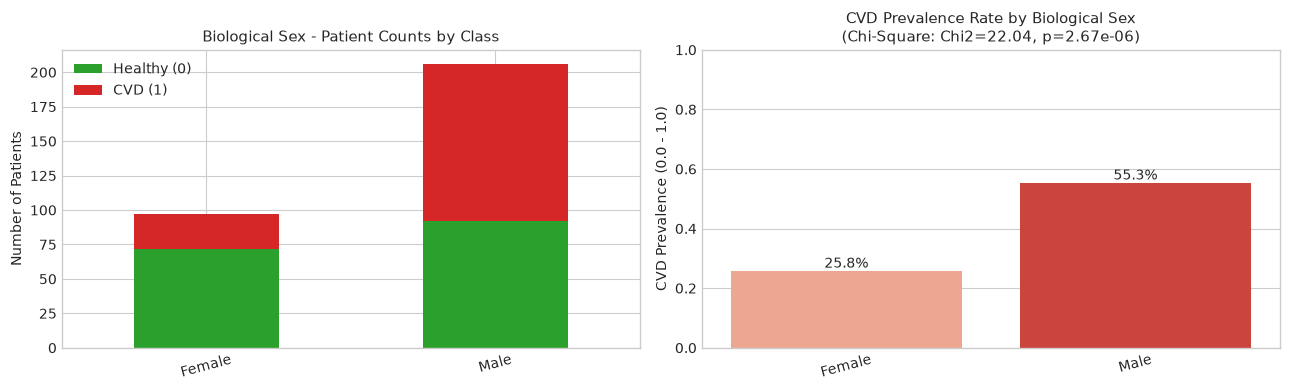

-> sex Disease Rates: Female: 25.8%, Male: 55.3%
--------------------------------------------------------------------------------


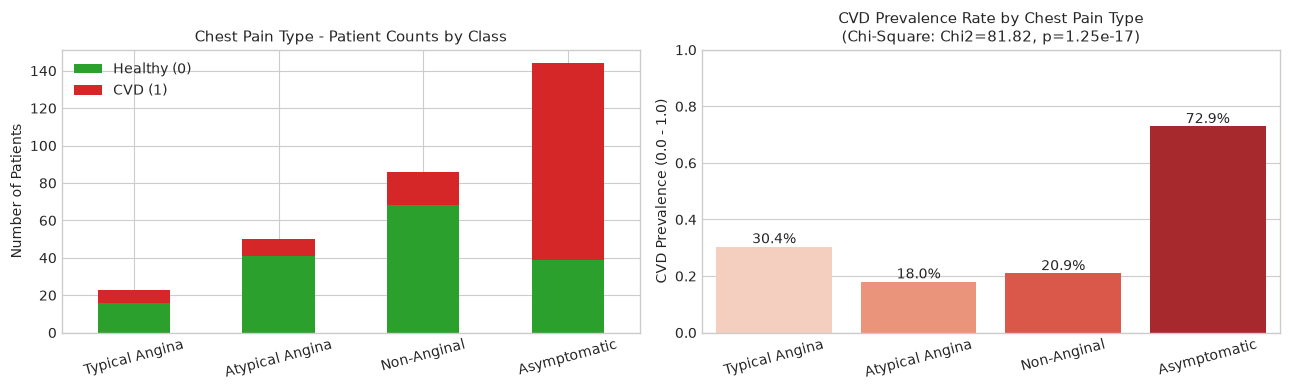

-> chest_pain_type Disease Rates: Typical Angina: 30.4%, Atypical Angina: 18.0%, Non-Anginal: 20.9%, Asymptomatic: 72.9%
--------------------------------------------------------------------------------


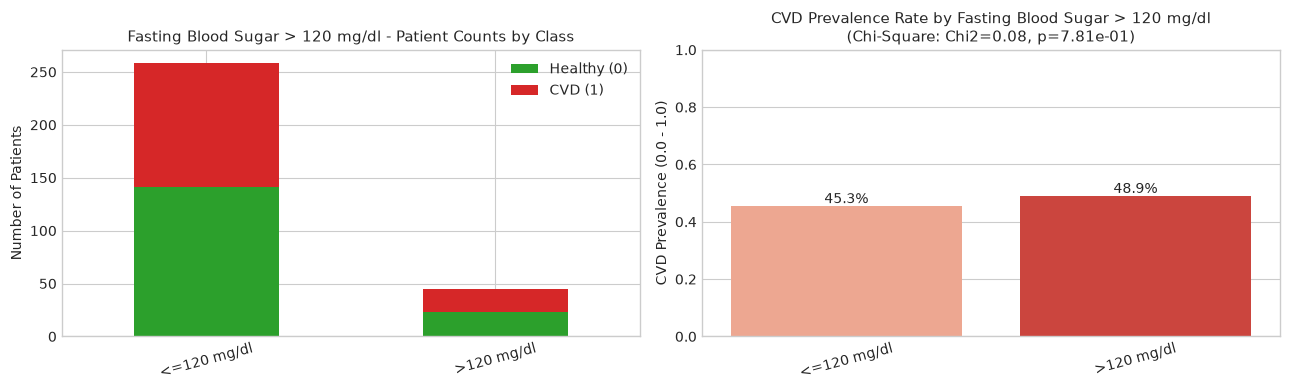

-> fasting_blood_sugar Disease Rates: <=120 mg/dl: 45.3%, >120 mg/dl: 48.9%
--------------------------------------------------------------------------------


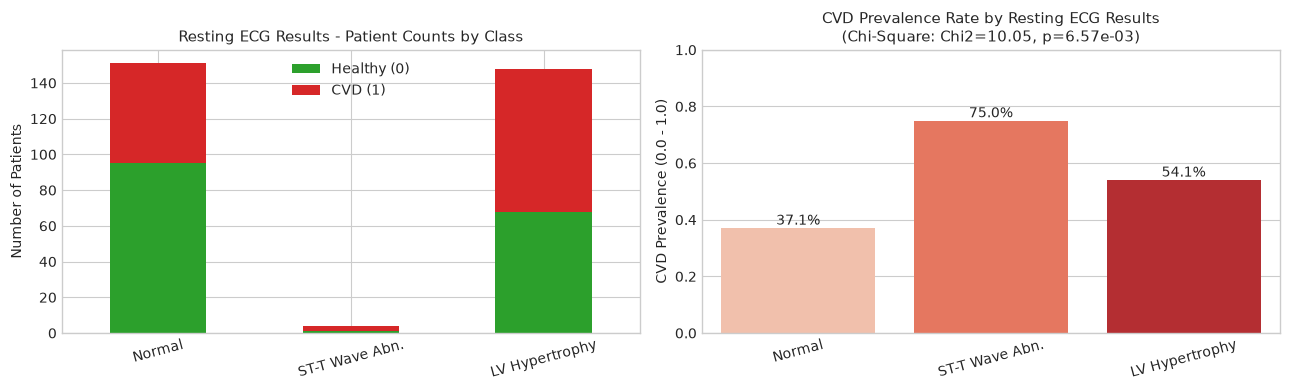

-> resting_ecg Disease Rates: Normal: 37.1%, ST-T Wave Abn.: 75.0%, LV Hypertrophy: 54.1%
--------------------------------------------------------------------------------


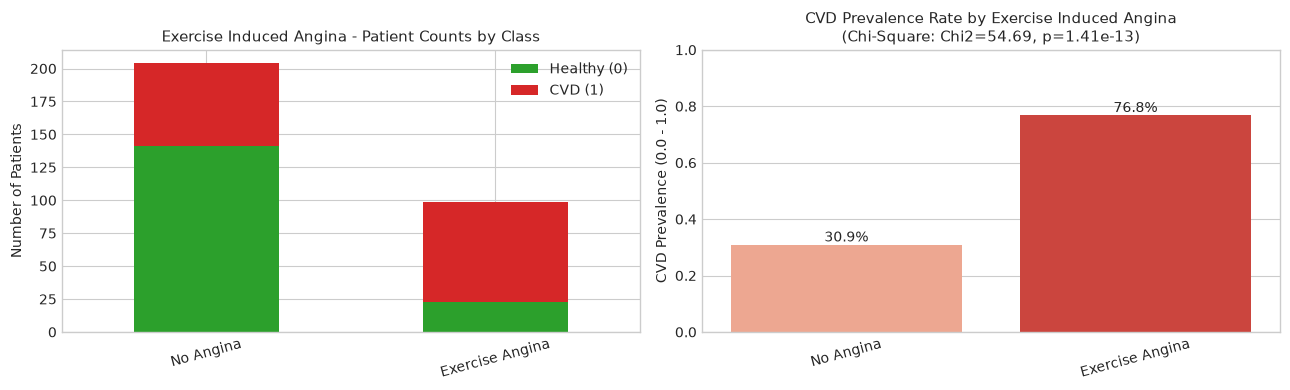

-> exercise_angina Disease Rates: No Angina: 30.9%, Exercise Angina: 76.8%
--------------------------------------------------------------------------------


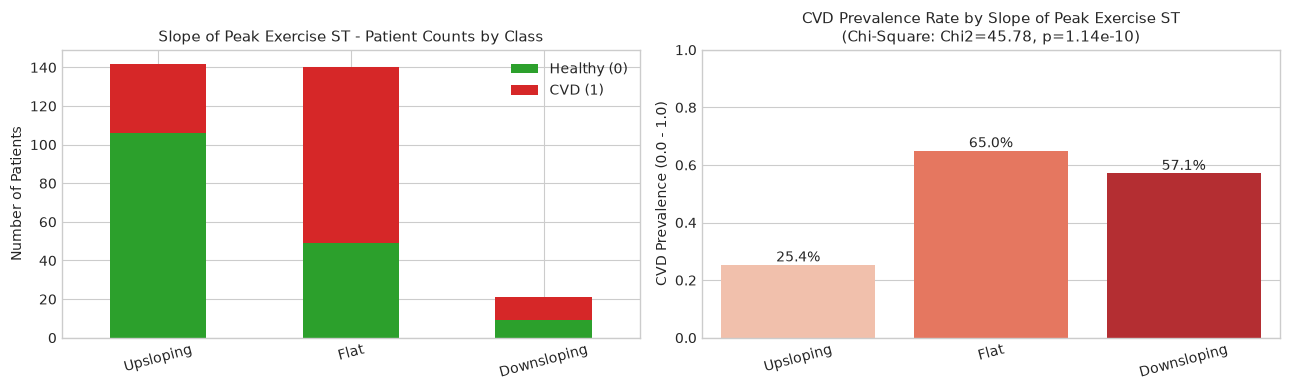

-> slope Disease Rates: Upsloping: 25.4%, Flat: 65.0%, Downsloping: 57.1%
--------------------------------------------------------------------------------


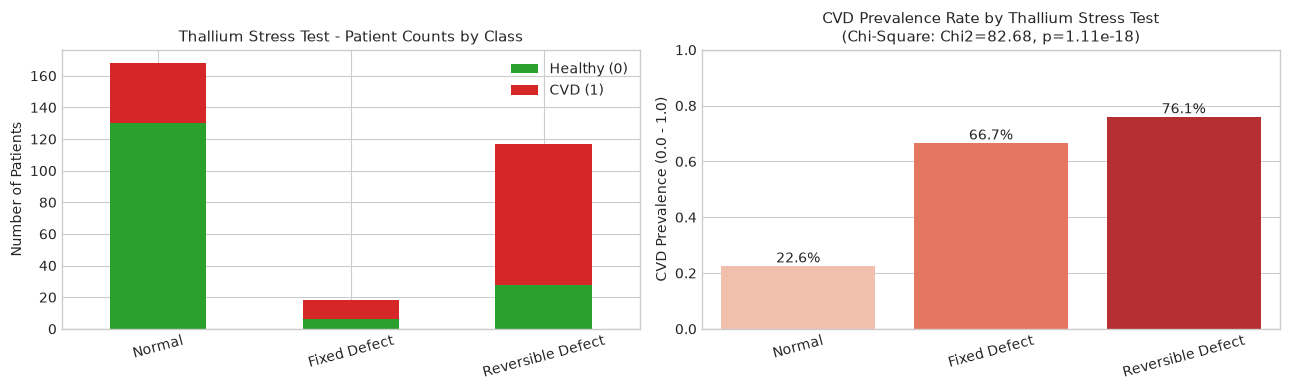

-> thal Disease Rates: Normal: 22.6%, Fixed Defect: 66.7%, Reversible Defect: 76.1%
--------------------------------------------------------------------------------


In [6]:
cat_features = [
    ('sex', 'Biological Sex', {0: 'Female', 1: 'Male'}),
    ('chest_pain_type', 'Chest Pain Type', {1: 'Typical Angina', 2: 'Atypical Angina', 3: 'Non-Anginal', 4: 'Asymptomatic'}),
    ('fasting_blood_sugar', 'Fasting Blood Sugar > 120 mg/dl', {0: '<=120 mg/dl', 1: '>120 mg/dl'}),
    ('resting_ecg', 'Resting ECG Results', {0: 'Normal', 1: 'ST-T Wave Abn.', 2: 'LV Hypertrophy'}),
    ('exercise_angina', 'Exercise Induced Angina', {0: 'No Angina', 1: 'Exercise Angina'}),
    ('slope', 'Slope of Peak Exercise ST', {1: 'Upsloping', 2: 'Flat', 3: 'Downsloping'}),
    ('thal', 'Thallium Stress Test', {3: 'Normal', 6: 'Fixed Defect', 7: 'Reversible Defect'})
]

for col, title, label_dict in cat_features:
    contingency = pd.crosstab(df_clean[col], df_clean['target'])
    chi2, p_val, _, _ = stats.chi2_contingency(contingency)
    
    # Calculate disease prevalence (% CVD) per category
    rates_df = df_clean.groupby(col)['target'].agg(['count', 'mean']).reset_index()
    rates_df['label'] = rates_df[col].map(label_dict)
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    # Subplot 1: Stacked Counts
    stacked_counts = df_clean.groupby([col, 'target']).size().unstack(fill_value=0)
    stacked_counts.index = stacked_counts.index.map(label_dict)
    stacked_counts.plot(kind='bar', stacked=True, color=['#2ca02c', '#d62728'], ax=axes[0])
    axes[0].set_title(f"{title} - Patient Counts by Class", fontsize=11)
    axes[0].set_xlabel('')
    axes[0].set_ylabel('Number of Patients')
    axes[0].legend(['Healthy (0)', 'CVD (1)'])
    axes[0].tick_params(axis='x', rotation=15)
    
    # Subplot 2: Prevalence Rate %
    sns.barplot(x='label', y='mean', data=rates_df, hue='label', palette='Reds', legend=False, ax=axes[1])
    axes[1].set_title(f"CVD Prevalence Rate by {title}\n(Chi-Square: Chi2={chi2:.2f}, p={p_val:.2e})", fontsize=11)
    axes[1].set_xlabel('')
    axes[1].set_ylabel('CVD Prevalence (0.0 - 1.0)')
    axes[1].set_ylim(0, 1.0)
    axes[1].tick_params(axis='x', rotation=15)
    for p in axes[1].patches:
        axes[1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10)
        
    plt.tight_layout()
    plt.show()
    
    rates_summary = ', '.join([f"{r['label']}: {r['mean']*100:.1f}%" for _, r in rates_df.iterrows()])
    print(f"-> {col} Disease Rates: {rates_summary}")
    print("-" * 80)

## 5. Correlation Analysis

We compute the complete Pearson correlation matrix among all features and display the top linear predictors of heart disease.

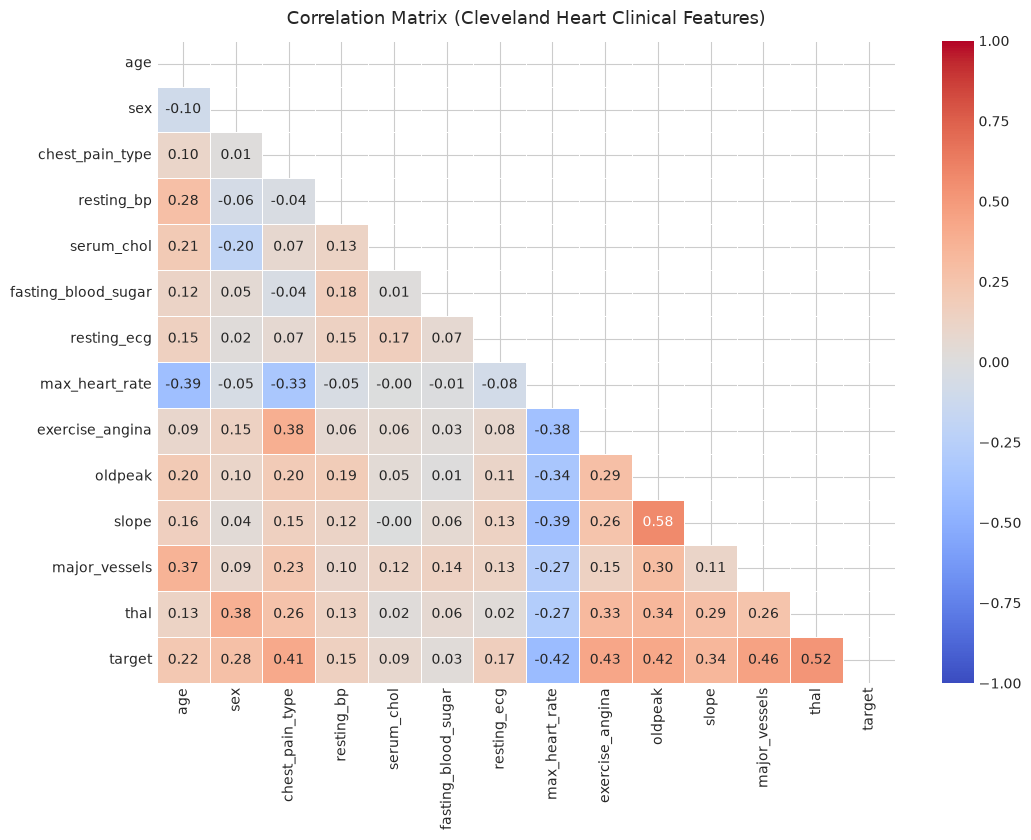

Features Ranked by Correlation with Heart Disease:
thal                   : +0.522
major_vessels          : +0.460
exercise_angina        : +0.432
oldpeak                : +0.425
chest_pain_type        : +0.414
slope                  : +0.339
sex                    : +0.277
age                    : +0.223
resting_ecg            : +0.169
resting_bp             : +0.151
serum_chol             : +0.085
fasting_blood_sugar    : +0.025
max_heart_rate         : -0.417


In [7]:
plt.figure(figsize=(11, 8.5))
corr_matrix = df_clean.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask, linewidths=0.5)
plt.title('Correlation Matrix (Cleveland Heart Clinical Features)', fontsize=13, pad=12)
plt.show()

# Top correlations with the target
target_corr = corr_matrix['target'].drop('target').sort_values(ascending=False)
print("Features Ranked by Correlation with Heart Disease:")
for feat, val in target_corr.items():
    print(f"{feat:22s} : {val:+.3f}")

## 6. Leak-Free Preprocessing Pipeline

In accordance with rigorous machine learning protocols (and addressing the leakage traps highlighted in the research paper):
1. **Stratified Split (80/20):** Split training and testing sets *before* performing any scaling, encoding, or sampling.
2. **Leak-Free Imputation:** Fit imputers strictly on `X_train` and transform `X_test`.
3. **Categorical One-Hot Encoding:** Fit `OneHotEncoder` strictly on `X_train` for nominal variables (`chest_pain_type`, `resting_ecg`, `slope`, `thal`), then transform `X_test`.
4. **Min-Max Scaling:** Scale continuous features to $[0, 1]$ fitting strictly on `X_train`.
5. **Training-Only SMOTE:** Balance classes using SMOTE *strictly on the training split*, preserving pristine testing distribution.

In [8]:
# 1. Stratified Train-Test Split (BEFORE any transformations)
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Initial Train Split Shape: {X_train.shape} | Targets: Healthy={sum(y_train==0)}, CVD={sum(y_train==1)}")
print(f"Initial Test Split Shape:  {X_test.shape}  | Targets: Healthy={sum(y_test==0)}, CVD={sum(y_test==1)}")

# 2. Leak-Free Imputation
num_imp = SimpleImputer(strategy='median')
cat_imp = SimpleImputer(strategy='most_frequent')

X_train_imp = X_train.copy()
X_test_imp = X_test.copy()

X_train_imp[num_cols] = num_imp.fit_transform(X_train[num_cols])
X_test_imp[num_cols] = num_imp.transform(X_test[num_cols])

X_train_imp[cat_cols] = cat_imp.fit_transform(X_train[cat_cols])
X_test_imp[cat_cols] = cat_imp.transform(X_test[cat_cols])

# 3. One-Hot Encoding for Nominal Attributes
nominal_cols = ['chest_pain_type', 'resting_ecg', 'slope', 'thal']
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_train = ohe.fit_transform(X_train_imp[nominal_cols])
ohe_test = ohe.transform(X_test_imp[nominal_cols])

ohe_cols = ohe.get_feature_names_out(nominal_cols)
df_ohe_tr = pd.DataFrame(ohe_train, columns=ohe_cols, index=X_train.index)
df_ohe_te = pd.DataFrame(ohe_test, columns=ohe_cols, index=X_test.index)

X_train_enc = pd.concat([X_train_imp.drop(columns=nominal_cols), df_ohe_tr], axis=1)
X_test_enc = pd.concat([X_test_imp.drop(columns=nominal_cols), df_ohe_te], axis=1)

# 4. Normalization via MinMaxScaler (Fitted on Train, Applied to Test)
scaler = MinMaxScaler()
feature_names_final = X_train_enc.columns
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_enc), columns=feature_names_final)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_enc), columns=feature_names_final)

# 5. Training-Only SMOTE Oversampling
smote = SMOTE(k_neighbors=5, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train.reset_index(drop=True))
X_train_final = pd.DataFrame(X_train_resampled, columns=feature_names_final)
y_train_final = pd.Series(y_train_resampled, name='target')

print("\n" + "="*60)
print("FINAL PREPROCESSED DATASET SPECIFICATIONS:")
print("="*60)
print(f"X_train Final Shape: {X_train_final.shape} | Balance: {np.bincount(y_train_final)}")
print(f"X_test Final Shape:  {X_test_scaled.shape}  | Balance: {np.bincount(y_test)}")
print(f"Total Transformed Feature Dimensions: {len(feature_names_final)}")
print("Transformed Columns:", list(feature_names_final))

Initial Train Split Shape: (242, 13) | Targets: Healthy=131, CVD=111
Initial Test Split Shape:  (61, 13)  | Targets: Healthy=33, CVD=28

FINAL PREPROCESSED DATASET SPECIFICATIONS:
X_train Final Shape: (262, 22) | Balance: [131 131]
X_test Final Shape:  (61, 22)  | Balance: [33 28]
Total Transformed Feature Dimensions: 22
Transformed Columns: ['age', 'sex', 'resting_bp', 'serum_chol', 'fasting_blood_sugar', 'max_heart_rate', 'exercise_angina', 'oldpeak', 'major_vessels', 'chest_pain_type_1.0', 'chest_pain_type_2.0', 'chest_pain_type_3.0', 'chest_pain_type_4.0', 'resting_ecg_0.0', 'resting_ecg_1.0', 'resting_ecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


## 7. Preprocessed Feature Matrices Inspection
Preview the clean, leak-free normalized training feature matrix.

In [9]:
X_train_final.head(10)

,age,sex,resting_bp,serum_chol,fasting_blood_sugar,max_heart_rate,exercise_angina,oldpeak,major_vessels,chest_pain_type_1.0,...,chest_pain_type_4.0,resting_ecg_0.0,resting_ecg_1.0,resting_ecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
0,0.395833,1.0,0.283019,0.337900,0.0,0.725191,0.0,0.080645,0.000000,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.541667,1.0,0.339623,0.310502,0.0,0.641221,0.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0.520833,0.0,0.358491,0.369863,1.0,0.671756,1.0,0.000000,0.333333,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.520833,1.0,0.132075,0.417808,0.0,0.648855,0.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.583333,0.0,0.433962,0.262557,0.0,0.396947,1.0,0.032258,0.000000,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
5,0.395833,1.0,0.339623,0.296804,1.0,0.603053,1.0,0.000000,0.666667,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
6,0.520833,1.0,0.283019,0.319635,0.0,0.290076,1.0,0.354839,0.333333,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
7,0.541667,1.0,0.433962,0.207763,0.0,0.305344,1.0,0.903226,0.000000,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
8,0.750000,0.0,0.575472,0.326484,0.0,0.587786,0.0,0.129032,0.000000,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
9,0.354167,1.0,0.433962,0.422374,0.0,0.374046,1.0,0.290323,0.666667,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
